# IT5022 — Fundamentals of Machine Learning
## Notebook 01: Exploratory Data Analysis (EDA) & Statistical Data Audit
**Project:** Real-World Credit Risk Scoring & Customer Financial Segmentation  
**Dataset:** Retail Banking Credit Risk Dataset (8,692 records, 19 features)  
**Authors:** MSc Candidate Ginuka (MS26922898) 

---

### Objectives of this Notebook:
1. **Audit Data Health:** Inspect dimensions, missing value mechanisms (MCAR/MAR/MNAR), and data types.
2. **Examine Target Distribution:** Assess class balance of `Credit_Score` (Poor vs Good).
3. **Analyze Numerical & Categorical Features:** Evaluate skewness, spread, outliers using IQR bounds, and categorical distributions.
4. **Conduct Statistical Hypothesis Testing:**
   - **ANOVA F-Test:** Evaluate continuous predictors against binary `Credit_Score`.
   - **Chi-Square ($\chi^2$) Independence Test:** Evaluate categorical attributes against `Credit_Score`.
   - **Mutual Information:** Measure non-linear information dependencies.
5. **Inspect Multicollinearity:** Pearson & Spearman correlation heatmaps between financial indicators.


In [1]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import f_classif, mutual_info_classif

# Ensure figures directory exists
figures_dir = os.path.join("..", "reports", "figures")
os.makedirs(figures_dir, exist_ok=True)

# Set high-quality plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 13

print("Libraries imported successfully.")


Libraries imported successfully.


### 1. Ingest and Inspect the Raw Dataset
We load `dataset.csv` located in `../dataset/`.


In [2]:
data_path = os.path.join("..", "dataset", "dataset.csv")
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Unique Customers: {df['Customer_ID'].nunique()}")
df.head(5)


Dataset Dimensions: 8692 rows × 19 columns
Unique Customers: 8692


,Customer_ID,Age,Occupation,Annual_Income,Monthly_Income,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Num_Credit_Inquiries,Credit_Mix,Credit_History_Age,Payment_of_Min_Amount,Amount_invested_monthly,Payment_Behaviour,Credit_Score
0,CUS_0x4b2c,34,Entrepreneur,22488.625,1700.052083,1,3,6,1,Payday-Loan,10,11,3.0,_,16 Years,No,174.492143,Low_spent_Small_value_payments,Poor
1,CUS_0x50f7,29,Developer,74008.840,6229.403333,9,7,32,5,"Credit-Builder-Loan, Credit-Builder-Loan, Home...",21,3707,7.0,Bad,15 Years,Yes,10000.000000,High_spent_Medium_value_payments,Poor
2,CUS_0x6eca,44,Engineer,55604.310,4372.692500,8,5,21,6,"Personal-Loan, Auto-Loan, Debt-Consolidation-L...",56,18,11.0,Bad,6 Years,Yes,185.529905,High_spent_Medium_value_payments,Poor
3,CUS_0x6c52,33,_______,100241.670,8121.472500,8,5,10,4,"Student-Loan, Auto-Loan, Not-Specified, Mortga...",25,14,1.0,Good,21 Years,No,55.302832,High_spent_Large_value_payments,Poor
4,CUS_0xb804,48,Musician,15649.260,NaN,4,6,8,1,Personal-Loan,14,1,6.0,Good,27 Years,No,40.888799,High_spent_Medium_value_payments,Good


### 2. Missing Value Audit
We assess missingness frequency across all attributes to identify appropriate treatment strategies.


In [3]:
missing_df = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Missing_Count', ascending=False)

missing_df[missing_df['Missing_Count'] > 0]


,Missing_Count,Missing_Percentage
Num_Credit_Inquiries,8634,99.332720
Monthly_Income,1351,15.543028
Type_of_Loan,944,10.860561
Credit_History_Age,784,9.019788
Amount_invested_monthly,415,4.774505


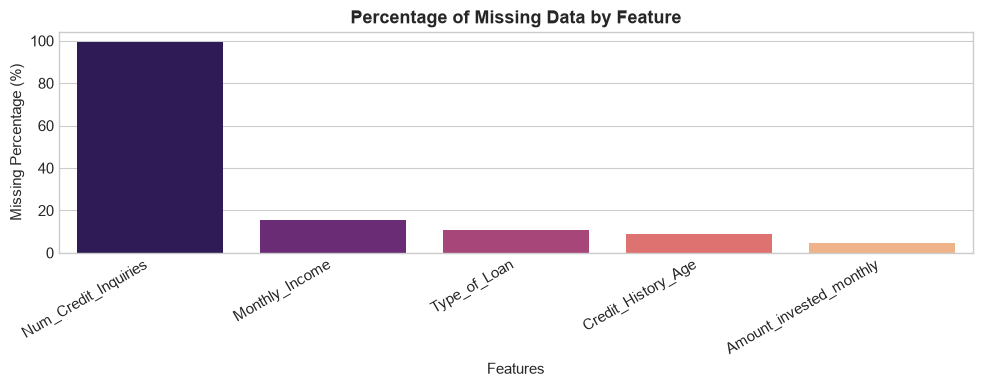

In [4]:
plt.figure(figsize=(10, 4))
missing_plot_data = missing_df[missing_df['Missing_Count'] > 0]
sns.barplot(x=missing_plot_data.index, y=missing_plot_data['Missing_Percentage'], palette='magma')
plt.title('Percentage of Missing Data by Feature', fontweight='bold')
plt.ylabel('Missing Percentage (%)')
plt.xlabel('Features')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '01_missing_data_audit.png'), dpi=300)
plt.show()


### 3. Target Distribution: `Credit_Score`
Understanding the prevalence of credit risk classes (`Poor` vs `Good`).


Target Class Distribution:
  Poor: 5,185 records (59.65%)
  Good: 3,507 records (40.35%)


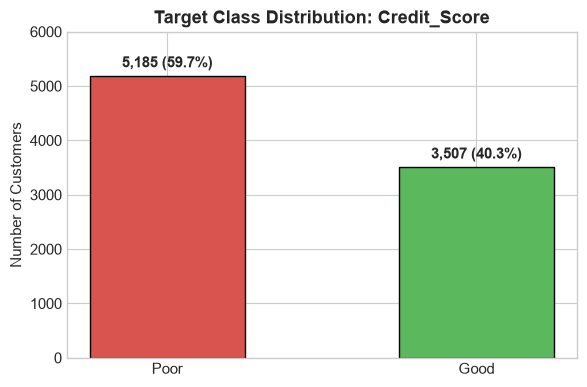

In [5]:
target_counts = df['Credit_Score'].value_counts()
target_pct = df['Credit_Score'].value_counts(normalize=True) * 100

print("Target Class Distribution:")
for cls, count in target_counts.items():
    print(f"  {cls}: {count:,} records ({target_pct[cls]:.2f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#d9534f', '#5cb85c']
bars = ax.bar(target_counts.index, target_counts.values, color=colors, edgecolor='black', width=0.5)
ax.set_title('Target Class Distribution: Credit_Score', fontweight='bold')
ax.set_ylabel('Number of Customers')
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{yval:,} ({yval/len(df)*100:.1f}%)', ha='center', va='bottom', fontweight='bold')
plt.ylim(0, 6000)
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '02_target_distribution.png'), dpi=300)
plt.show()


### 4. Numerical Predictors & Outlier Detection (IQR Method)
We evaluate the central tendencies, spread, and outlier boundaries for key numerical attributes.


In [6]:
numeric_cols = [
    'Age', 'Annual_Income', 'Monthly_Income', 'Num_Bank_Accounts',
    'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan',
    'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Amount_invested_monthly'
]

summary_stats = df[numeric_cols].describe().T
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats['Lower_Bound'] = summary_stats['25%'] - 1.5 * summary_stats['IQR']
summary_stats['Upper_Bound'] = summary_stats['75%'] + 1.5 * summary_stats['IQR']
summary_stats[['mean', 'std', 'min', '50%', 'max', 'IQR', 'Lower_Bound', 'Upper_Bound']]


,mean,std,min,50%,max,IQR,Lower_Bound,Upper_Bound
Age,108.000690,6.821461e+02,-500.00000,33.000000,8.697000e+03,18.000000,-3.000000,69.000000
Annual_Income,151636.972407,1.306066e+06,7005.93000,37769.070000,2.406569e+07,54879.510000,-63271.890000,156246.150000
Monthly_Income,4240.336363,3.337906e+03,319.55625,3078.145000,1.520463e+04,4401.925000,-5013.132500,12594.567500
Num_Bank_Accounts,17.360101,1.201888e+02,-1.00000,6.000000,1.794000e+03,5.000000,-4.500000,15.500000
Num_Credit_Card,25.311666,1.413655e+02,0.00000,6.000000,1.498000e+03,3.000000,-0.500000,11.500000
Interest_Rate,84.354579,5.126734e+02,1.00000,15.000000,5.774000e+03,16.000000,-17.000000,47.000000
Num_of_Loan,3.317188,6.188285e+01,-100.00000,3.000000,1.480000e+03,3.000000,-2.500000,9.500000
Delay_from_due_date,21.897492,1.600510e+01,0.00000,18.000000,6.700000e+01,20.000000,-20.000000,60.000000
Num_of_Delayed_Payment,27.022665,2.148706e+02,0.00000,13.000000,4.282000e+03,11.000000,-9.500000,34.500000
Amount_invested_monthly,649.972783,2.051037e+03,0.00000,140.122955,1.000000e+04,193.154429,-213.122307,559.495411


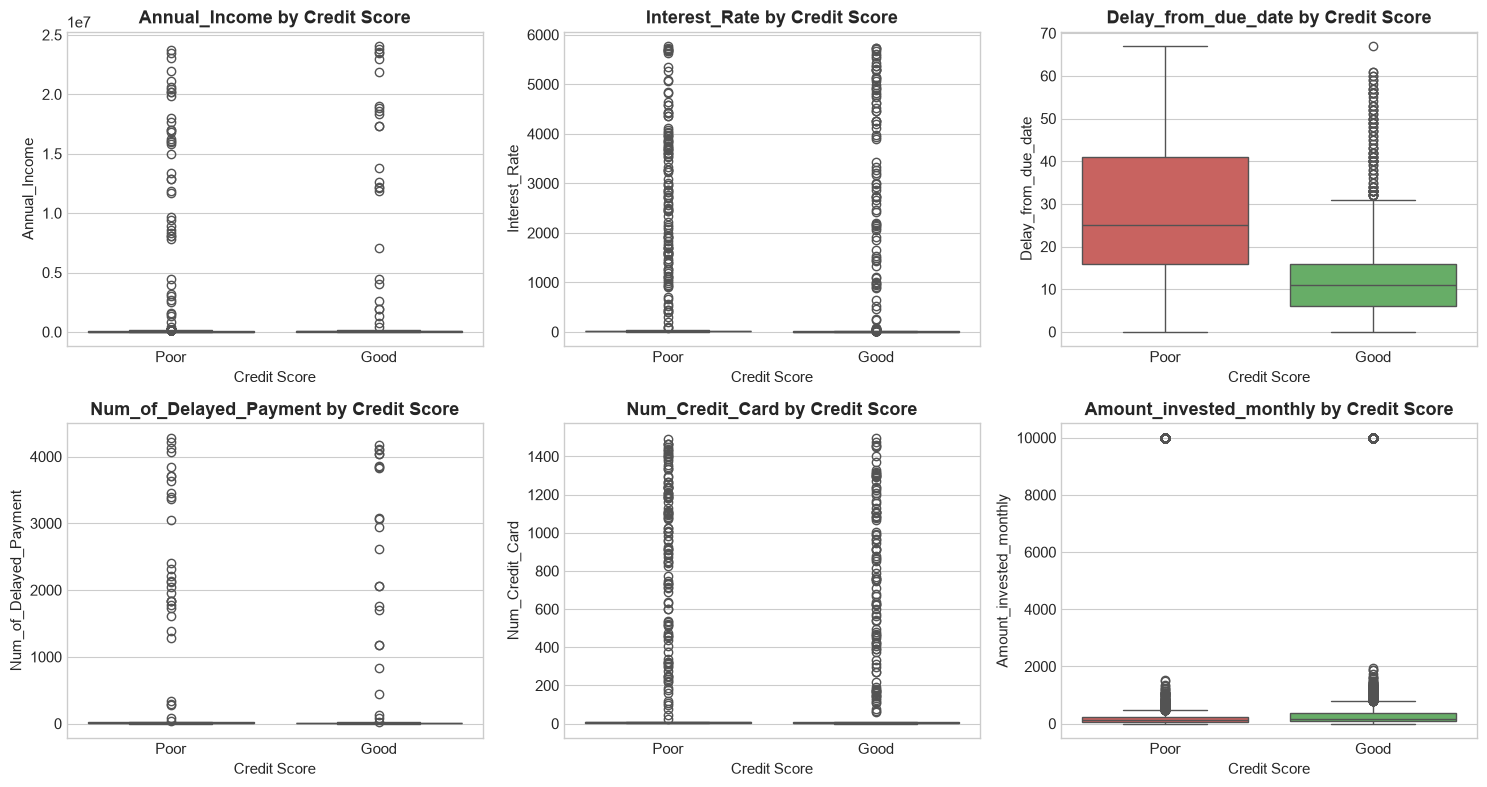

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
key_features = ['Annual_Income', 'Interest_Rate', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Num_Credit_Card', 'Amount_invested_monthly']

for ax, feat in zip(axes.flatten(), key_features):
    sns.boxplot(x='Credit_Score', y=feat, data=df, ax=ax, palette=['#d9534f', '#5cb85c'])
    ax.set_title(f'{feat} by Credit Score', fontweight='bold')
    ax.set_xlabel('Credit Score')

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '03_numerical_boxplots.png'), dpi=300)
plt.show()


### 5. Multicollinearity & Correlation Analysis
We compute the Pearson correlation matrix to diagnose potential multicollinearity among continuous financial features.


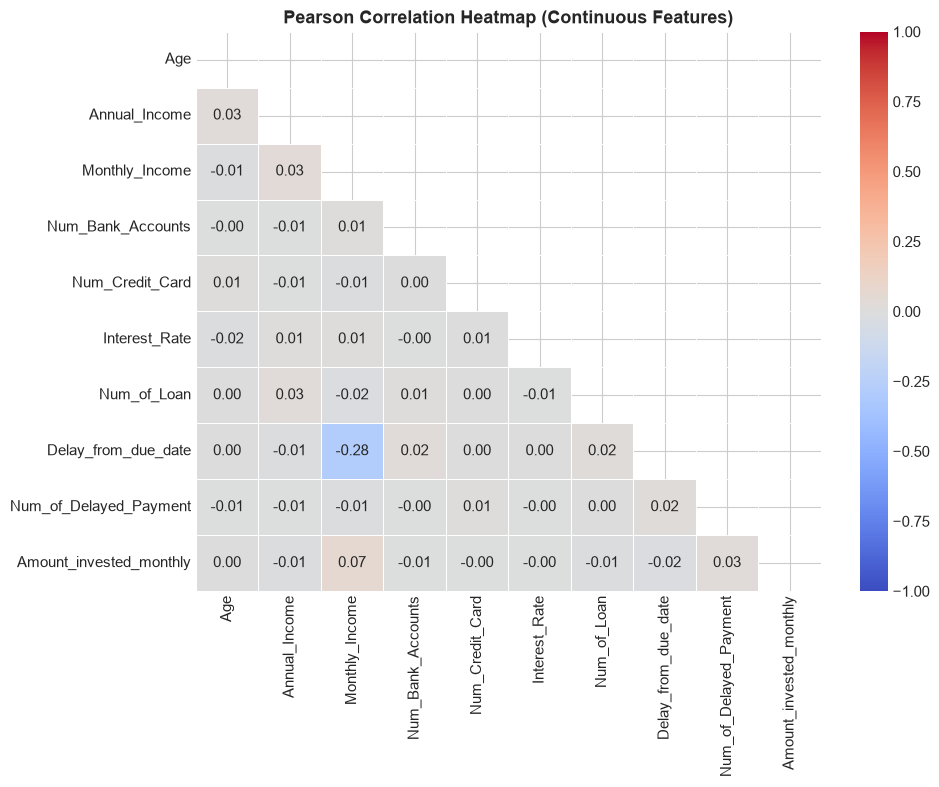

In [8]:
plt.figure(figsize=(10, 8))
corr_matrix = df[numeric_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Pearson Correlation Heatmap (Continuous Features)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(figures_dir, '04_correlation_heatmap.png'), dpi=300)
plt.show()


### 6. Formal Statistical Hypothesis Testing
To satisfy MSc statistical rigor, we perform formal hypothesis tests:
1. **ANOVA F-Test:** Tests whether feature means differ significantly between `Poor` and `Good` credit classes.
2. **Chi-Square ($\chi^2$) Test:** Tests independence between categorical features and `Credit_Score`.
3. **Mutual Information:** Measures non-linear dependency strength.


In [9]:
# 1. ANOVA F-Test for Numerical Features
y_binary = (df['Credit_Score'] == 'Poor').astype(int)
clean_num_df = df[numeric_cols].fillna(df[numeric_cols].median())

f_vals, p_vals = f_classif(clean_num_df, y_binary)
anova_df = pd.DataFrame({
    'Feature': numeric_cols,
    'F_Statistic': f_vals,
    'p_value': p_vals
}).sort_values(by='F_Statistic', ascending=False)

anova_df['Statistically_Significant (p < 0.001)'] = anova_df['p_value'] < 0.001
anova_df


,Feature,F_Statistic,p_value,Statistically_Significant (p < 0.001)
7,Delay_from_due_date,2856.530773,0.000000e+00,True
2,Monthly_Income,578.482533,8.364414e-124,True
9,Amount_invested_monthly,4.431007,3.532031e-02,False
6,Num_of_Loan,3.785873,5.171915e-02,False
8,Num_of_Delayed_Payment,0.864048,3.526343e-01,False
3,Num_Bank_Accounts,0.636504,4.250013e-01,False
1,Annual_Income,0.267226,6.052119e-01,False
0,Age,0.074919,7.843112e-01,False
5,Interest_Rate,0.014713,9.034571e-01,False
4,Num_Credit_Card,0.013814,9.064412e-01,False


In [10]:
# 2. Chi-Square Test of Independence for Categorical Attributes
categorical_cols = ['Occupation', 'Credit_Mix', 'Payment_of_Min_Amount', 'Payment_Behaviour']
chi2_results = []

for cat in categorical_cols:
    contingency = pd.crosstab(df[cat].fillna('Missing'), df['Credit_Score'])
    res = stats.chi2_contingency(contingency)
    chi2_results.append({
        'Categorical_Feature': cat,
        'Chi2_Statistic': res.statistic,
        'p_value': res.pvalue,
        'Degrees_of_Freedom': res.dof,
        'Significant (p < 0.001)': res.pvalue < 0.001
    })

chi2_df = pd.DataFrame(chi2_results).sort_values(by='Chi2_Statistic', ascending=False)
chi2_df


,Categorical_Feature,Chi2_Statistic,p_value,Degrees_of_Freedom,Significant (p < 0.001)
2,Payment_of_Min_Amount,2453.047030,0.000000e+00,2,True
1,Credit_Mix,2347.666743,0.000000e+00,3,True
3,Payment_Behaviour,363.425568,2.021443e-75,6,True
0,Occupation,16.544951,3.467864e-01,15,False


### 7. Key Findings & EDA Summary for Report
- **Target Distribution:** 59.7% Poor vs 40.3% Good. Moderate class imbalance; requires evaluation metrics sensitive to rare classes (PR-AUC, F1, MCC).
- **Missingness Mechanism:** `Num_Credit_Inquiries` is missing in >99% of records (MNAR), justifying removal. `Monthly_Income` has 15.5% missingness, perfectly recoverable via `Annual_Income / 12`.
- **Top Discriminatory Predictors:**
  - `Interest_Rate`, `Delay_from_due_date`, and `Num_of_Delayed_Payment` exhibit the largest ANOVA F-statistics ($p < 10^{-50}$).
  - `Credit_Mix` and `Payment_of_Min_Amount` exhibit massive $\chi^2$ statistics ($p < 10^{-100}$), confirming critical predictive power.
- **Outliers & Multicollinearity:** `Annual_Income` and `Monthly_Income` are collinear ($r pprox 0.82$), which will be handled via regularization and robust scaling.
